### Segundo Parcial Inferencia estadística y reconocimiento de patrones. 

### ALUMNAS: Parallela Luciana Sol y Gonzalez Camila Belen. 

### Algoritmo: Regresión logística. 

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import OneHotEncoder 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score,roc_curve, auc
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize


In [9]:
data = pd.read_csv("/Users/Camila/Desktop/Segundo Parcial /regresión.csv")
data.head(6)

,duracion,paginas,acciones,valor,clase
0,7.0,2,4,8,2
1,21.0,2,6,6,2
2,57.0,2,4,4,2
3,101.0,3,6,12,2
4,109.0,2,6,12,2
5,125.0,5,10,20,2


Realizamos análisis exploratorio:
1. Nombres de las columnas.
2. Cuantas filas tenemos y el total de datos.
3. Cuantos valores nulos tenemos.
4. Si las clases estan balanceadas

In [4]:
data.columns 

Index(['duracion', 'paginas', 'acciones', 'valor', 'clase'], dtype='object')

In [5]:
data.shape

(170, 5)

Vemos que la base no tiene valores nulos.

In [10]:
data.isna().sum()
data = data.dropna()



Verificamos si las clases están balanceadas:

In [6]:
data['clase'].value_counts()
data['clase'].value_counts(normalize = True) * 100 

clase
0    50.588235
2    25.882353
1    23.529412
Name: proportion, dtype: float64

Dividimos los datos en X e Y: 

In [11]:
X = data.iloc[:, : ]                        # Creamos la variable X que contiene todas las columnas

X.drop(columns=['clase'],inplace = True)

Y = data.loc[ : ,  ['clase']]                # la variable Y representa a las clases

Vemos que tan correlacionadas están las variables entre sí mediante una matriz de correlación. Podemos ver que las variables valor y acciones son las variables más correlacionadas
entre sí. También podemos decir que las variables acciones y páginas también están correlacionadas. Las variables con menor correlación son duración y valor, seguidas por 
duracion y acciones. 

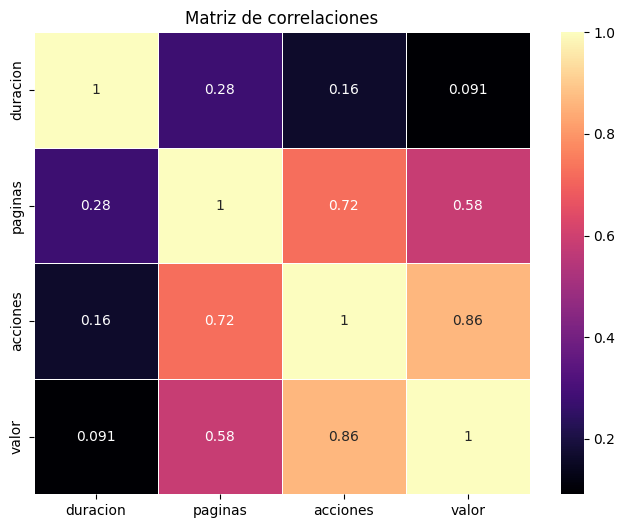

          duracion  paginas  acciones  valor
duracion     1.000    0.278     0.163  0.091
paginas      0.278    1.000     0.724  0.584
acciones     0.163    0.724     1.000  0.863
valor        0.091    0.584     0.863  1.000


In [12]:
matriz_correlacion = round(X.corr(),3)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacion, annot=True, cmap='magma', linewidths=0.5)
plt.title("Matriz de correlaciones")
plt.show()
print(matriz_correlacion)

### Realizamos el preprocesamiento de los datos: 

Primero estandarizamos las variables y luego dividimos los datos en entrenamiento y prueba. 

In [13]:
Scaler = StandardScaler()
X_scaled = Scaler.fit_transform(X)

In [39]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42, stratify=Y) 

Aplicamos el algoritmo de la regresión logistica para predecir la variable clase. 

In [47]:
model = LogisticRegression(
        class_weight='balanced',
        solver="sag",
        max_iter=1000,
        multi_class="multinomial",
        random_state=42)

model.fit(X_train, Y_train)
y_pred = model.predict(X_test)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


### Realizamos matriz de confusión y métricas para evaluar el funcionamiento del algoritmo. 


📊 **Resultados del Modelo de Regresión Logística**
**Exactitud (Accuracy):** 0.7059 (Proporción de aciertos totales)
**Precisión (Precision):** 0.7073 (De las que predijimos como una clase cuantas eran correctas)
**Sensibilidad o Recall:** 0.7059 (De las que *realmente* eran de esa clase, cuántas detectamos)


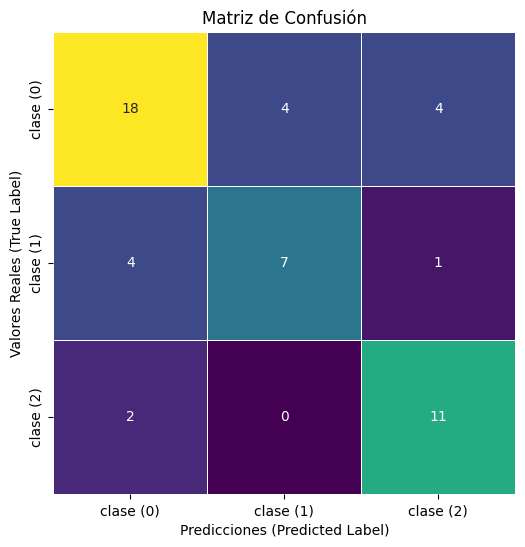

In [48]:
accuracy = accuracy_score(Y_test, y_pred)
precision = precision_score(Y_test, y_pred, average='weighted')
recall = recall_score(Y_test, y_pred, average='weighted')
cm = confusion_matrix(Y_test, y_pred)

print("\n" + "="*50)
print("📊 **Resultados del Modelo de Regresión Logística**")
print("="*50)
print(f"**Exactitud (Accuracy):** {accuracy:.4f} (Proporción de aciertos totales)")
print(f"**Precisión (Precision):** {precision:.4f} (De las que predijimos como una clase cuantas eran correctas)")
print(f"**Sensibilidad o Recall:** {recall:.4f} (De las que *realmente* eran de esa clase, cuántas detectamos)")


class_labels = ['clase (0)', 'clase (1)', 'clase (2)'] 

plt.figure(figsize=(8, 6))
sns.heatmap(cm,
            annot=True,              
            fmt='d',                 
            cmap='viridis',          
            cbar=False,
            linewidths=0.5,
            linecolor='white',
            square=True,
            xticklabels=class_labels,
            yticklabels=class_labels
           )
plt.title('Matriz de Confusión')
plt.ylabel('Valores Reales (True Label)')
plt.xlabel('Predicciones (Predicted Label)')
plt.show()

## Creamos la curva ROC para evaluar el desempeño del algoritmo por cada clase y luego de manera general

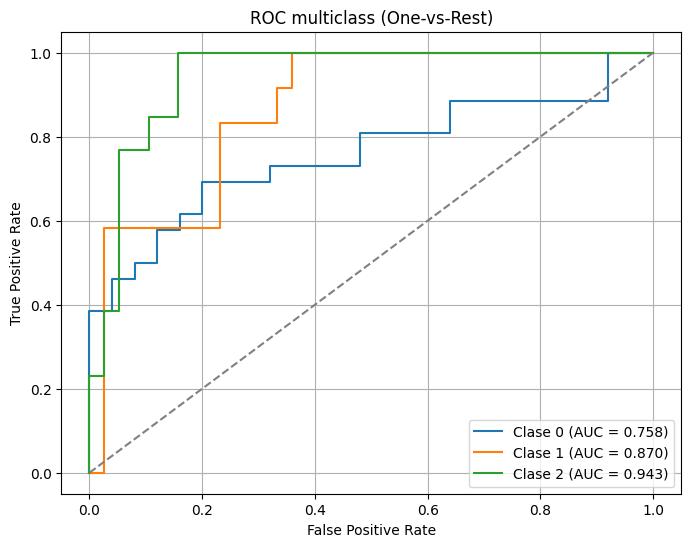

In [50]:
# 1. Obtener probabilidades predictivas
y_prob = model.predict_proba(X_test)

# 2. Binarizar las etiquetas verdaderas (one-vs-rest)
classes = np.unique(Y_train)
Y_test_bin = label_binarize(Y_test, classes=classes)

# 3. ROC por clase
fpr = dict()
tpr = dict()
roc_auc = dict()

for i, cls in enumerate(classes):
    fpr[i], tpr[i], _ = roc_curve(Y_test_bin[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# 4. Graficar
plt.figure(figsize=(8, 6))
for i, cls in enumerate(classes):
    plt.plot(fpr[i], tpr[i],
             label=f"Clase {cls} (AUC = {roc_auc[i]:.3f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC multiclass (One-vs-Rest)")
plt.legend()
plt.grid(True)
plt.show()


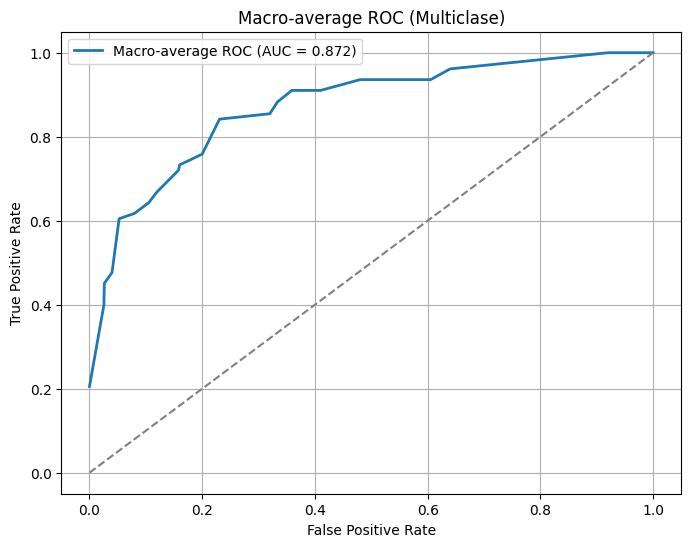

In [51]:
# Probabilidades del modelo
y_prob = model.predict_proba(X_test)

# Clases
classes = np.unique(Y_train)

# Binarizar etiquetas
Y_test_bin = label_binarize(Y_test, classes=classes)

# ROC por clase
fpr = dict()
tpr = dict()
roc_auc = dict()

for i, cls in enumerate(classes):
    fpr[i], tpr[i], _ = roc_curve(Y_test_bin[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# MACRO-AVERAGE ROC

# 1. Unir todos los puntos únicos de FPR
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(classes))]))

# 2. Interpolar los TPR de cada clase en all_fpr
mean_tpr = np.zeros_like(all_fpr)
for i in range(len(classes)):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

# 3. Promedio de TPR entre clases
mean_tpr /= len(classes)

# 4. AUC macro
macro_auc = auc(all_fpr, mean_tpr)

# 5. Graficar curva macro
plt.figure(figsize=(8, 6))
plt.plot(all_fpr, mean_tpr, label=f"Macro-average ROC (AUC = {macro_auc:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Macro-average ROC (Multiclase)")
plt.legend()
plt.grid(True)
plt.show()
